# Effect of transforming the targets in regression model: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/compose/plot_transformed_target.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/compose/plot_transformed_target.html)).

**Scenario:** a linear ridge model fitted on a strongly skewed target, without and with
`TransformedTargetRegressor`: first with `func=np.log1p, inverse_func=np.expm1` on synthetic
`make_regression` data, then with `transformer=QuantileTransformer(n_quantiles=900,
output_distribution="normal")` on the Ames housing prices.

**Adaptations:**
- **RidgeCV is a GAP** in Moxie (`moxie.linear_model` has `Ridge` but no `RidgeCV`). The Python
  cells run the example unchanged with `RidgeCV`; each fitted `alpha_` is then passed to
  `Ridge(alpha=alpha_)` on both sides, which is the model `RidgeCV` refits after selecting alpha.
  Parity compares Moxie against sklearn `Ridge(alpha_)` (same model and data).
- **Ames housing is downloaded** by the example (`fetch_openml`), so the second part uses a
  synthetic stand-in of the same size (1460 rows, 33 numeric features) with a right-skewed
  positive price target in k$. The `TransformedTargetRegressor(QuantileTransformer)` code path is
  unchanged; on this stand-in the transformation does not improve R2 as it does on Ames, which is a
  property of the substituted data, identical on both sides.
- `PredictionErrorDisplay` plots are drawn for both sides from the predictions (dpi 70).
- Extra check, not in the example: `check_inverse=True` with a non-inverse pair warns on both sides.

**Determinism:** deterministic. `make_regression`/`train_test_split` use fixed seeds and are run in
Python; `QuantileTransformer` does not subsample (1095 training rows < `subsample=10000`), so
both fits are deterministic and numerical parity is required.


In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("compose/plot_transformed_target")

## 1. scikit-learn (Python reference)

Synthetic example, as in the gallery script.

In [2]:
import warnings
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.metrics import median_absolute_error, r2_score
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import RidgeCV, Ridge
from sklearn.metrics import PredictionErrorDisplay

plt.rcParams["figure.dpi"] = 70

X, y = make_regression(n_samples=10_000, noise=100, random_state=0)
y = np.expm1((y + abs(y.min())) / 200)
y_trans = np.log1p(y)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)


def compute_score(y_true, y_pred):
    return {
        "R2": f"{r2_score(y_true, y_pred):.3f}",
        "MedAE": f"{median_absolute_error(y_true, y_pred):.3f}",
    }


ridge_cv = RidgeCV().fit(X_train, y_train)
y_pred_ridge = ridge_cv.predict(X_test)

ridge_cv_with_trans_target = TransformedTargetRegressor(
    regressor=RidgeCV(), func=np.log1p, inverse_func=np.expm1
).fit(X_train, y_train)
y_pred_ridge_with_trans_target = ridge_cv_with_trans_target.predict(X_test)
print("RidgeCV alpha_ (raw target):", ridge_cv.alpha_,
      "| (log target):", ridge_cv_with_trans_target.regressor_.alpha_)
print("raw:", compute_score(y_test, y_pred_ridge))
print("log1p/expm1:", compute_score(y_test, y_pred_ridge_with_trans_target))

# Parity reference: the refitted models at the selected alphas.
a_raw, a_log = float(ridge_cv.alpha_), float(ridge_cv_with_trans_target.regressor_.alpha_)
sk_raw = Ridge(alpha=a_raw).fit(X_train, y_train).predict(X_test)
sk_ttr = TransformedTargetRegressor(Ridge(alpha=a_log), func=np.log1p, inverse_func=np.expm1).fit(X_train, y_train)
sk_log = sk_ttr.predict(X_test)
sk_log_score = sk_ttr.score(X_test, y_test)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    TransformedTargetRegressor(Ridge(alpha=a_log), func=np.log1p, inverse_func=np.exp).fit(X_train, y_train)
sk_inverse_warnings = sum("not strictly inverse" in str(w.message) for w in caught)
print("RidgeCV vs Ridge(alpha_) max |diff|:", np.abs(sk_raw - y_pred_ridge).max(),
      np.abs(sk_log - y_pred_ridge_with_trans_target).max())
nb.share(X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test,
         alphas=np.array([a_raw, a_log]))

RidgeCV alpha_ (raw target): 10.0 | (log target): 10.0
raw: {'R2': '0.405', 'MedAE': '67.482'}
log1p/expm1: {'R2': '0.657', 'MedAE': '22.620'}
RidgeCV vs Ridge(alpha_) max |diff|: 1.1652900866465643e-12 7.048583938740194e-12


Ames housing stand-in: 1460 rows, 33 numeric features, a right-skewed positive price in k$
(the gallery's `fetch_openml(name="house_prices")` needs the network). The example code below it is unchanged.

raw: {'R2': '0.432', 'MedAE': '20.870'}
quantile: {'R2': '0.419', 'MedAE': '20.088'}


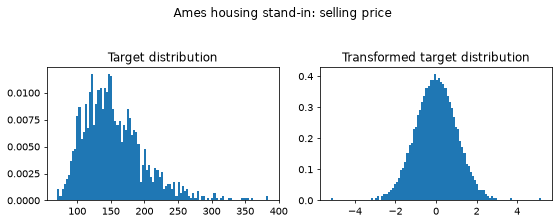

In [3]:
from sklearn.preprocessing import QuantileTransformer, quantile_transform

rng = np.random.RandomState(42)
X_ames = rng.lognormal(mean=1.0, sigma=0.6, size=(1460, 33))
coef = rng.uniform(0.0, 0.3, size=33)
y_ames = 20.0 + np.exp(3.2 + 0.09 * (X_ames @ coef) + rng.normal(scale=0.25, size=1460))
X, y = X_ames, y_ames
y_trans = quantile_transform(y.reshape(-1, 1), n_quantiles=900, output_distribution="normal", copy=True).squeeze()

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(8, 3))
ax0.hist(y, bins=100, density=True); ax0.set_title("Target distribution")
ax1.hist(y_trans, bins=100, density=True); ax1.set_title("Transformed target distribution")
f.suptitle("Ames housing stand-in: selling price", y=1.05)
plt.tight_layout()

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=1)

ridge_cv = RidgeCV().fit(X_train, y_train)
model_with_transformer = TransformedTargetRegressor(
    regressor=RidgeCV(),
    transformer=QuantileTransformer(n_quantiles=900, output_distribution="normal"),
).fit(X_train, y_train)
print("raw:", compute_score(y_test, ridge_cv.predict(X_test)))
print("quantile:", compute_score(y_test, model_with_transformer.predict(X_test)))

b_raw, b_q = float(ridge_cv.alpha_), float(model_with_transformer.regressor_.alpha_)
sk_ames_raw = Ridge(alpha=b_raw).fit(X_train, y_train).predict(X_test)
sk_q = TransformedTargetRegressor(
    regressor=Ridge(alpha=b_q),
    transformer=QuantileTransformer(n_quantiles=900, output_distribution="normal"),
).fit(X_train, y_train)
sk_ames_q = sk_q.predict(X_test)
sk_quantiles = sk_q.transformer_.quantiles_
nb.share(A_train=X_train, b_train=y_train, A_test=X_test, b_test=y_test,
         ames_alphas=np.array([b_raw, b_q]))

## 2. Moxie (native Mojo)

The same four models: `Ridge` alone and inside `TransformedTargetRegressor` with typed `log1p`/`expm1`
functions (synthetic data), then `Ridge` alone and with a `QuantileTransformer` target transformer
(Ames stand-in). Learning and prediction run in Mojo; Python only supplies arrays and the alphas.

In [4]:
%%mojo transformed_target
from moxie.compose import TransformedTargetRegressor
from moxie.linear_model import Ridge
from moxie.preprocessing import QuantileTransformer
from moxie_nb_io import load, save, save_floats
from numojo import NDArray
from std.math import log1p, expm1, exp


def apply_log1p(y: NDArray[DType.float64]) raises -> NDArray[DType.float64]:
    var out = y.copy()
    for i in range(out.size):
        out.unsafe_set(i, log1p(out.unsafe_get(i)))
    return out^


def apply_expm1(y: NDArray[DType.float64]) raises -> NDArray[DType.float64]:
    var out = y.copy()
    for i in range(out.size):
        out.unsafe_set(i, expm1(out.unsafe_get(i)))
    return out^


def apply_exp(y: NDArray[DType.float64]) raises -> NDArray[DType.float64]:
    var out = y.copy()
    for i in range(out.size):
        out.unsafe_set(i, exp(out.unsafe_get(i)))
    return out^


def main() raises:
    var X_train = load("X_train")
    var y_train = load("y_train")
    var X_test = load("X_test")
    var y_test = load("y_test")
    var alphas = load("alphas")
    var a_raw = Float64(alphas.unsafe_get(0))
    var a_log = Float64(alphas.unsafe_get(1))

    var ridge = Ridge(alpha=a_raw)
    _ = ridge.fit(X_train, y_train)
    save("raw", ridge.predict(X_test))

    var model = TransformedTargetRegressor(Ridge(alpha=a_log), func=apply_log1p, inverse_func=apply_expm1)
    _ = model.fit(X_train, y_train)
    save("log", model.predict(X_test))
    var scores = List[Float64]()
    scores.append(model.score(X_test, y_test))

    var wrong = TransformedTargetRegressor(Ridge(alpha=a_log), func=apply_log1p, inverse_func=apply_exp)
    _ = wrong.fit(X_train, y_train)
    scores.append(Float64(len(wrong.warnings_)))
    save_floats("scores", scores)

    var A_train = load("A_train")
    var b_train = load("b_train")
    var A_test = load("A_test")
    var ames_alphas = load("ames_alphas")
    var plain = Ridge(alpha=Float64(ames_alphas.unsafe_get(0)))
    _ = plain.fit(A_train, b_train)
    save("ames_raw", plain.predict(A_test))
    var quantile = TransformedTargetRegressor(
        Ridge(alpha=Float64(ames_alphas.unsafe_get(1))),
        transformer=QuantileTransformer(n_quantiles=900, output_distribution="normal"))
    _ = quantile.fit(A_train, b_train)
    save("ames_quantile", quantile.predict(A_test))
    save("quantiles", quantile.transformer_.value().quantiles_)
    print("warnings from the non-inverse pair:", len(wrong.warnings_))

warnings from the non-inverse pair: 2


## 3. Side by side and parity

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
synthetic Ridge(alpha_) predict,PASS,"(2500,)","(2500,)",1.53e-12,8.19e-12,"rtol=1e-09, atol=1e-09",,"same ridge normal equations; Moxie solves in Float64 with its own factorization while sklearn uses LAPACK, so results agree to rounding amplified by the condition number"
synthetic TTR(log1p/expm1) predict,PASS,"(2500,)","(2500,)",2.1e-07,1.91e-10,"rtol=1e-09, atol=1e-09",,"same ridge normal equations; Moxie solves in Float64 with its own factorization while sklearn uses LAPACK, so results agree to rounding amplified by the condition number; expm1 preserves relative error"
synthetic TTR score (R2),PASS,(),(),1.48e-11,2.25e-11,"rtol=1e-10, atol=0",,R2 of predictions that agree to ~2e-10 relative (expm1 amplifies the ridge rounding)
check_inverse warning count,PASS,(),(),,,exact,0 mismatches,
Ames stand-in Ridge(alpha_) predict,PASS,"(365,)","(365,)",5.68e-13,3.01e-15,"rtol=1e-09, atol=1e-09",,"same ridge normal equations; Moxie solves in Float64 with its own factorization while sklearn uses LAPACK, so results agree to rounding amplified by the condition number"
Ames stand-in QuantileTransformer quantiles_,PASS,"(900, 1)","(900, 1)",0,0,"rtol=1e-12, atol=1e-12",,linear interpolation of order statistics in Float64 on both sides
Ames stand-in TTR(QuantileTransformer) predict,PASS,"(365,)","(365,)",7.96e-13,3.87e-15,"rtol=1e-08, atol=1e-08",,"same ridge normal equations; Moxie solves in Float64 with its own factorization while sklearn uses LAPACK, so results agree to rounding amplified by the condition number; the inverse normal CDF and quantile interpolation add a few ulps"
RidgeCV,GAP,,,,,,moxie.linear_model has no RidgeCV; both sides use Ridge at sklearn's selected alpha_,
fetch_openml Ames housing,ADAPTED,,,,,,network download replaced by a seeded synthetic stand-in of the same shape,


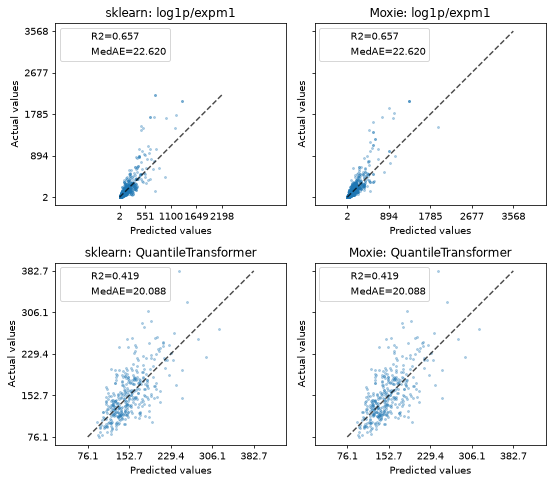

In [5]:
mx = nb.results["transformed_target"]
y_syn_test = np.load(nb.inputs / "y_test.npy")  # y_test now holds the Ames split
f, axes = plt.subplots(2, 2, sharey="row", figsize=(8, 7))
for ax, pred, title in [(axes[0, 0], sk_log, "sklearn: log1p/expm1"), (axes[0, 1], mx["log"], "Moxie: log1p/expm1"),
                        (axes[1, 0], sk_ames_q, "sklearn: QuantileTransformer"),
                        (axes[1, 1], mx["ames_quantile"], "Moxie: QuantileTransformer")]:
    truth = y_test if "Quantile" in title else y_syn_test
    PredictionErrorDisplay.from_predictions(truth, pred, kind="actual_vs_predicted", ax=ax,
                                            scatter_kwargs={"alpha": 0.3, "s": 4})
    for name, score in compute_score(truth, pred).items():
        ax.plot([], [], " ", label=f"{name}={score}")
    ax.legend(loc="upper left"); ax.set_title(title)
plt.tight_layout()

moxie_nb.side_by_side(sklearn=sk_log[:6], moxie=mx["log"][:6])
moxie_nb.side_by_side(sklearn_scores={**compute_score(y_syn_test, sk_log)}, moxie_scores={**compute_score(y_syn_test, mx["log"])})
reason_ridge = ("same ridge normal equations; Moxie solves in Float64 with its own factorization while "
                "sklearn uses LAPACK, so results agree to rounding amplified by the condition number")
nb.compare("synthetic Ridge(alpha_) predict", sk_raw, mx["raw"], rtol=1e-9, atol=1e-9, reason=reason_ridge)
nb.compare("synthetic TTR(log1p/expm1) predict", sk_log, mx["log"], rtol=1e-9, atol=1e-9,
           reason=reason_ridge + "; expm1 preserves relative error")
nb.compare("synthetic TTR score (R2)", sk_log_score, mx["scores"][0], rtol=1e-10,
           reason="R2 of predictions that agree to ~2e-10 relative (expm1 amplifies the ridge rounding)")
nb.compare("check_inverse warning count", sk_inverse_warnings, int(mx["scores"][1]), exact=True)
nb.compare("Ames stand-in Ridge(alpha_) predict", sk_ames_raw, mx["ames_raw"], rtol=1e-9, atol=1e-9, reason=reason_ridge)
nb.compare("Ames stand-in QuantileTransformer quantiles_", sk_quantiles, mx["quantiles"], rtol=1e-12, atol=1e-12,
           reason="linear interpolation of order statistics in Float64 on both sides")
nb.compare("Ames stand-in TTR(QuantileTransformer) predict", sk_ames_q, mx["ames_quantile"], rtol=1e-8, atol=1e-8,
           reason=reason_ridge + "; the inverse normal CDF and quantile interpolation add a few ulps")
nb.note("RidgeCV", "GAP", "moxie.linear_model has no RidgeCV; both sides use Ridge at sklearn's selected alpha_")
nb.note("fetch_openml Ames housing", "ADAPTED", "network download replaced by a seeded synthetic stand-in of the same shape")
nb.report()
nb.assert_parity()